# code_074 · Regularization and high-dimensional fitting

**Book:** section 15.3. A self-contained transparent response-model laboratory with generated records, explicit source assumptions and preserved provenance. Prerequisites: Python arrays/tables and Chapter 8's information contracts. Restart and run all cells. Imports, helpers and inputs are internal; ordinary execution needs no files, network, credentials, GPU or private module. Use the [quickstart](../README.md), [pinned environment](../requirements-lock.txt), [guide](../CHAPTER_15_GUIDE.md), [run evidence](../CHAPTER_15_EXECUTION.md) and [registry](../CODE_EXAMPLES.md#code_074).

Reference: CPython 3.14.3, NumPy 2.4.4, SciPy 1.17.1, pandas 3.0.3, Matplotlib 3.11.0, scikit-learn 1.9.0, CPU. Allow a minute to execute and 30–60 minutes to interpret. These scoped experiments expose task/data and fixed fitting controls rather than claim exhaustive estimator API coverage. Splits, fitted transformations, model selection and assessment declare their evidence boundaries locally. Synthetic cohort sizes and prevalences are constructed rather than population estimates. All numerical data are generated. These comparisons expose structural assumptions, information boundaries and transformation contracts without field-validity, causal or universal physical-model claims.


In [1]:
import platform,time,json
import numpy as np
import scipy,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn
from IPython.display import display
START=time.perf_counter();SEED=1574;rng=np.random.default_rng(SEED)
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'scikit-learn':sklearn.__version__}
print(VERSIONS);print('CPU:',platform.system(),platform.machine(),'seed:',SEED)
plt.rcParams.update({'figure.dpi':110,'font.size':11,'axes.spines.top':False,'axes.spines.right':False,'figure.constrained_layout.use':True})
RESULTS={}


{'python': '3.14.3', 'numpy': '2.4.4', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.0'}
CPU: Darwin arm64 seed: 1574


<a id="penalties"></a>
## Align the penalty convention before comparing paths

Training90, development120, final400 independent generated records have twelve sensor summaries. A and B measure the same latent z with .015 noise; target=2*z+.6*sensorC+Normal(.5). Common objective: SSE/(2n)+lambda*[rho*L1+(1-rho)*L2²/2], unpenalized intercept. Therefore sklearn Ridge alpha=n*lambda, Lasso alpha=lambda and ElasticNet alpha=lambda,l1_ratio=.5. Each family chooses lambda from twelve fixed values by development MSE. Standardization fits training rows. The path figure uses the SAME dataset and lambda axis for Ridge and Lasso; correlated A/B and useful C are marked, other sensors gray. No final selection or truth-driven parameter adjustment.


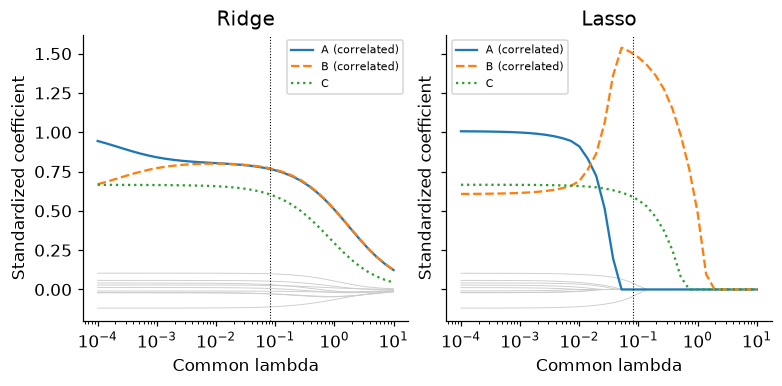

In [2]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge,Lasso,ElasticNet
from sklearn.metrics import mean_squared_error
def generate(n):
 z=rng.normal(size=n);a=rng.normal(size=(n,12));a[:,0]=z+rng.normal(0,.015,n);a[:,1]=z+rng.normal(0,.015,n);return a,2*z+.6*a[:,2]+rng.normal(0,.5,n)
X,y=generate(90);Xd,yd=generate(120);Xt,yt=generate(400);scale=StandardScaler().fit(X);A=scale.transform(X);Ad=scale.transform(Xd);At=scale.transform(Xt)
def estimator(family,lam,n):return Ridge(alpha=n*lam) if family=='Ridge' else Lasso(alpha=lam,max_iter=20000,tol=1e-7) if family=='Lasso' else ElasticNet(alpha=lam,l1_ratio=.5,max_iter=20000,tol=1e-7)
lambdas=np.logspace(-3,.5,12);chosen={};fits={};metrics=[]
for family in ['Ridge','Lasso','ElasticNet']:
 candidates=[estimator(family,l,len(y)).fit(A,y) for l in lambdas];scores=[mean_squared_error(yd,m.predict(Ad)) for m in candidates];j=int(np.argmin(scores));chosen[family]=float(lambdas[j]);fits[family]=candidates[j];metrics.append({'family':family,'lambda':chosen[family],'development_mse':float(scores[j]),'final_mse':float(mean_squared_error(yt,fits[family].predict(At))),'original_scale_coefficients':(fits[family].coef_/scale.scale_).tolist()})
assert np.corrcoef(X[:,:2].T)[0,1]>.99;np.testing.assert_allclose(A.mean(axis=0),0,atol=1e-12);assert all(np.isfinite([r['final_mse'] for r in metrics]))
RESULTS['selected_fits']=metrics;RESULTS['common_objective']='SSE/(2n)+lambda*(rho*L1+(1-rho)*L2_squared/2); intercept unpenalized';RESULTS['sensor_A_B_correlation']=float(np.corrcoef(X[:,:2].T)[0,1]);RESULTS['roles']={'train':90,'development':120,'final':400}
path_lambda=np.logspace(-4,1,36);fig,axes=plt.subplots(1,2,figsize=(7,3.4),sharex=True,sharey=True)
for ax,family in zip(axes,['Ridge','Lasso']):
 coefs=np.array([estimator(family,l,len(y)).fit(A,y).coef_ for l in path_lambda]);ax.plot(path_lambda,coefs[:,3:],color='.8',lw=.6)
 for j,(name,style) in enumerate([('A (correlated)','-'),('B (correlated)','--'),('C',':')]):ax.plot(path_lambda,coefs[:,j],style,label=name)
 ax.axvline(chosen[family],color='black',ls=':',lw=.7);ax.set(xscale='log',xlabel='Common lambda',ylabel='Standardized coefficient',title=family);ax.legend(fontsize=7)
plt.show()


<a id="stability"></a>
## Refitting measures conditional sensitivity, not newly collected evidence

Sixty training-row bootstrap draws refit each scaler and chosen penalty. Penalty choices remain fixed rather than repeating selection, so this is conditional fitting stability. Coefficients are converted to original sensor units before comparison. Final covariates are a fixed probe for prediction SD; their labels never choose a penalty or resampling rule. Correlated coefficient allocation and prediction sensitivity can differ. Selection frequency at tolerance1e-6 is descriptive and not a formal stability-selection error guarantee.


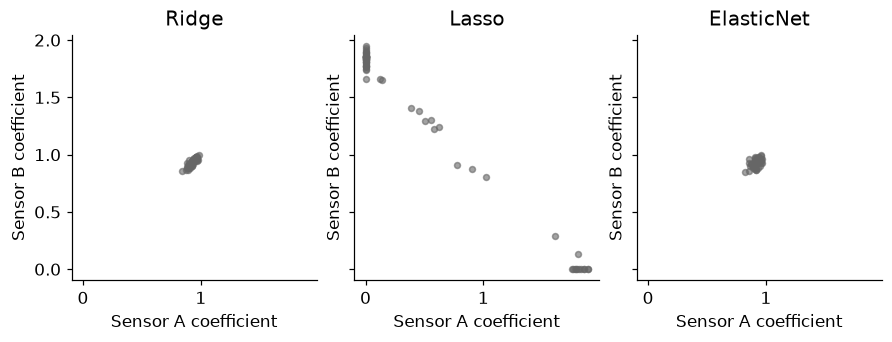

In [3]:
boot={name:[] for name in fits};predictions={name:[] for name in fits}
for _ in range(60):
 ids=rng.integers(0,len(y),len(y));sc=StandardScaler().fit(X[ids]);a=sc.transform(X[ids])
 for family in fits:
  model=estimator(family,chosen[family],len(ids)).fit(a,y[ids]);boot[family].append(model.coef_/sc.scale_);predictions[family].append(model.predict(sc.transform(Xt)))
rows=[];fig,axes=plt.subplots(1,3,figsize=(8,3),sharex=True,sharey=True)
for ax,family in zip(axes,fits):
 b=np.array(boot[family]);p=np.array(predictions[family]);assert b.shape==(60,12) and np.isfinite(p).all();rows.append({'family':family,'A_B_coefficient_sd':b[:,:2].std(axis=0,ddof=1).tolist(),'A_B_sum_sd':float(b[:,:2].sum(axis=1).std(ddof=1)),'selection_frequency':(np.abs(b)>1e-6).mean(axis=0).tolist(),'mean_final_probe_prediction_sd':float(p.std(axis=0,ddof=1).mean())});ax.scatter(b[:,0],b[:,1],s=15,color='.4',alpha=.6);ax.set(xlabel='Sensor A coefficient',ylabel='Sensor B coefficient',title=family)
RESULTS['conditional_bootstrap']=rows;RESULTS['bootstrap_draws']=60;plt.show()
# Separate p>n algebra audit; no held-out predictive ranking is inferred here.
H=rng.normal(size=(24,40));hy=rng.normal(size=24);hb=np.linalg.lstsq(H,hy,rcond=None)[0];null=np.linalg.svd(H,full_matrices=True)[2][-1];hr=np.linalg.solve(H.T@H+.1*np.eye(40),H.T@hy)
assert np.linalg.matrix_rank(H)==24;np.testing.assert_allclose(H@hb,hy,atol=1e-10);np.testing.assert_allclose(H@(hb+null),hy,atol=1e-10);assert np.linalg.norm(hr)<np.linalg.norm(hb)
RESULTS['p_greater_than_n_audit']={'rows':24,'columns':40,'rank':24,'minimum_norm_training_mse':float(np.mean((hy-H@hb)**2)),'Ridge_training_mse_at_penalty_point_1':float(np.mean((hy-H@hr)**2)),'null_direction_preserves_interpolation':True,'held_out_generalization_tested':False}


In [4]:
summary={'example_id':'code_074','seed':SEED,'versions':VERSIONS,'hardware':platform.system()+' '+platform.machine()+' CPU','concepts_demonstrated':['Ridge Lasso ElasticNet common penalty convention', 'training-only standardization and development selection', 'correlated sensor coefficient paths', 'bootstrap coefficient and prediction stability'],'results':RESULTS,'elapsed_seconds':round(time.perf_counter()-START,3)}
print('EXECUTION_SUMMARY_JSON:'+json.dumps(summary,sort_keys=True,allow_nan=False))


EXECUTION_SUMMARY_JSON:{"concepts_demonstrated": ["Ridge Lasso ElasticNet common penalty convention", "training-only standardization and development selection", "correlated sensor coefficient paths", "bootstrap coefficient and prediction stability"], "elapsed_seconds": 0.724, "example_id": "code_074", "hardware": "Darwin arm64 CPU", "results": {"bootstrap_draws": 60, "common_objective": "SSE/(2n)+lambda*(rho*L1+(1-rho)*L2_squared/2); intercept unpenalized", "conditional_bootstrap": [{"A_B_coefficient_sd": [0.029083791637830026, 0.03202504772942464], "A_B_sum_sd": 0.059038123299848144, "family": "Ridge", "mean_final_probe_prediction_sd": 0.1757744253296349, "selection_frequency": [1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0]}, {"A_B_coefficient_sd": [0.7350855049614079, 0.7386845928856243], "A_B_sum_sd": 0.056579183487905624, "family": "Lasso", "mean_final_probe_prediction_sd": 0.1058860293589634, "selection_frequency": [0.4, 0.8166666666666667, 1.0, 0.15, 0.5833333333333